# Bandidos $k$ armados

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Reto 1
Crea un bandido de Bernoulli para el problema del sitio web. Defina las probabilidades del banner verde y azul.
* La clase puede generalizarse para una maquina de K banners.

In [2]:

class BernoulliBandit:
    """ Maquina tragamonedas multi-armada de Bernoulli, la entrada K significa el numero de brazos (banner) """
    def __init__(self, K):
        self.probs = np.array([0.05 , 0.4])   # Defina las probabilidades de los banner
        #self.probs = np.random.uniform(size=K)  # Genera aleatoriamente K numeros del 0 al 1 como premios de jalar (click) cada brazo (boton)
        # probabilidad
        self.best_idx = np.argmax(self.probs)  # El brazo (banner) con mayor probabilidad de ganar
        self.best_prob = self.probs[self.best_idx]  # Probabilidad maxima de ganar
        self.K = K

    def step(self, k):
        # Cuando el jugador selecciona el brazo k, la probabilidad  de jalar (click) el brazo (boton) k de la maquina traga monedas (sitio web)
        # para obtener la recompensa regresa 1 (ganar) o 0 (no ganar)
        if np.random.rand() < self.probs[k]:
            return 1
        else:
            return 0
            
np.random.seed(1)  # Se usa una semilla para que los experimentos sean repetibles
K = 2   # Numero de brazos (banner)
bandit = BernoulliBandit(K)
print("El brazo con mayor probabilidad de ganar es %d, y su probabilidad de ganar es %.4f" %
      (bandit.best_idx, bandit.best_prob))

El brazo con mayor probabilidad de ganar es 1, y su probabilidad de ganar es 0.4000


## Reto 2 y Reto 3
Crea una funcion que calcule el lamento y que corra el experimento num_steps

In [5]:
class Solver:
    """ La base del algoritmo de bandido multi-armado """
    def __init__(self, bandit):
        self.bandit = bandit
        self.N = np.zeros(self.bandit.K)  # numero de intentos por brazo (banner)
        self.regret = 0.  # Lamento acumulado para el paso actual
        self.actions = []  # mantener una lista, guardar las acciones de cada paso
        self.regrets = []  # mantener una lista, guardar los lamentos acumulados en cada paso

    def update_regret(self, k):
        # Calcular el lamento acumulado y guardarlo, k es el numero de brazo (banner) seleccionado para esta accion
        self.regret += self.bandit.best_prob - self.bandit.probs[k]
        self.regrets.append(self.regret)

    def run_one_step(self):
        # Regresa que brazo (banner) es seleccionado para la accion actual, implementada para cada estrategia especifica
        raise NotImplementedError

    def run(self, num_steps):
        # Corre un numero de veces, num_steps es el numero total de corridas
        for _ in range(num_steps):
            k = self.run_one_step()
            self.N[k] += 1
            self.actions.append(k)
            self.update_regret(k)

## Reto 4 y Reto 5
Crear el algoritmo epsilon-greedy en la funcion run_one_step.
* Incluir exploracion
* Incluir explotacion
* Actualizar el valor Q

In [6]:
class EpsilonGreedy(Solver):
    """ Algoritmo Epsilon greedy, hereda la clase Solver """
    def __init__(self, bandit, epsilon=0.01, init_prob=1.0):
        super(EpsilonGreedy, self).__init__(bandit)
        self.epsilon = epsilon
        # Inicializa la recompensa esperada aproximada de jalar (click) todos los brazos (botones)
        self.Q = np.array([init_prob] * self.bandit.K)

    def run_one_step(self):
        if np.random.random() < self.epsilon:
            k = np.random.randint(0,self.bandit.K)  # Seleccionar un brazo (banner) aleatoriamente
        else:
            k = np.argmax(self.Q)  # Elegir el brazo (banner) con mayor recompensa esperada aproximada
        r = self.bandit.step(k)  # Obtener la recompensa para esta accion
        self.Q[k] += 1/(self.N[k]+1)*(r - self.Q[k])
        return k

## Reto 6
Realizar una funcion que grafique el lamento acumulado y corra el algoritmo. Utilice diferentes valores de epsilon
* 5000 pasos de tiempo
* 10000 pasos de tiempo


The cumulative regret of the epsilon-greedy algorithm is： 42.350000000000094


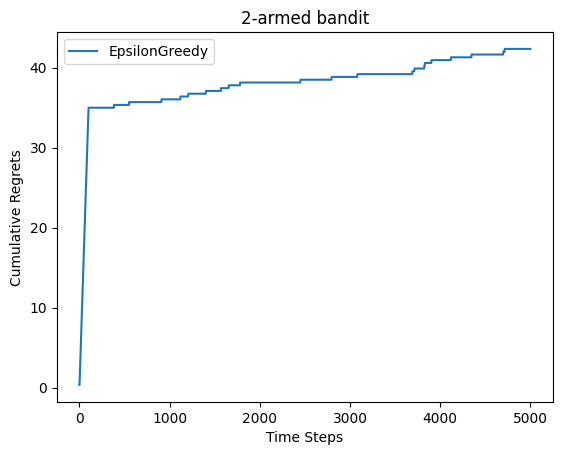

In [7]:
def plot_results(solvers, solver_names):
    """Genera una grafica de lamento acumulado en el tiempo. La entrada solvers es una lista, cada elemento
        es una estrategia especifica. Para solvers_name es una lista, guardando el nombre de cada estrategia"""
    for idx, solver in enumerate(solvers):
        time_list = range(len(solver.regrets))
        plt.plot(time_list, solver.regrets, label=solver_names[idx])
    plt.xlabel('Time Steps')
    plt.ylabel('Cumulative Regrets')
    plt.title('%d-armed bandit' % solvers[0].bandit.K)
    plt.legend()
    plt.show()


np.random.seed(1)
epsilon_greedy_solver = EpsilonGreedy(bandit, epsilon = 0.01)
epsilon_greedy_solver.run(5000)
print('The cumulative regret of the epsilon-greedy algorithm is：', epsilon_greedy_solver.regret)
plot_results([epsilon_greedy_solver], ["EpsilonGreedy"])

In [8]:
actions = np.array(epsilon_greedy_solver.actions).T.tolist()
print(actions)

[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

## Reto 7
Pruebe diferentes epsilons y vea como se comporta el algoritmo
* eps = 1e-4
* eps = 0.01
* eps = 0.1
* eps = 0.25
* eps = 0.5

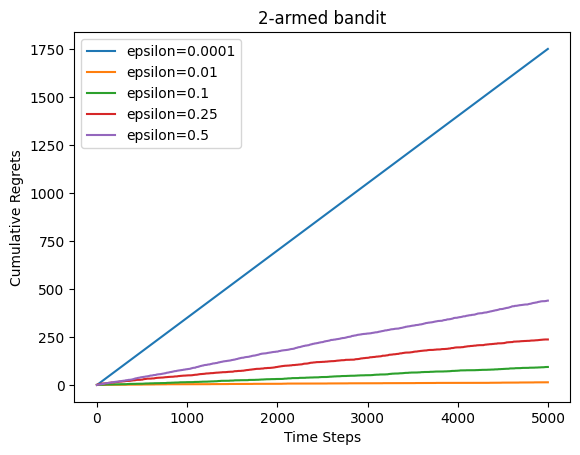

In [9]:
np.random.seed(0)
epsilons = [1e-4,0.01,0.1,0.25,0.5]
epsilon_greedy_solver_list = [
    EpsilonGreedy(bandit, epsilon=e) for e in epsilons
]
epsilon_greedy_solver_names = ["epsilon={}".format(e) for e in epsilons]
for solver in epsilon_greedy_solver_list:
    solver.run(5000)

plot_results(epsilon_greedy_solver_list, epsilon_greedy_solver_names)

## Reto 8

Modifique el algoritmo de epsilon-greedy con un epsilon = 1 y decaiga proporcionalmente al numero de iteraciones total_count.

El lamento acumulado del algoritmo epsilon-greedy con decaimiento de epsilon es： 1.05


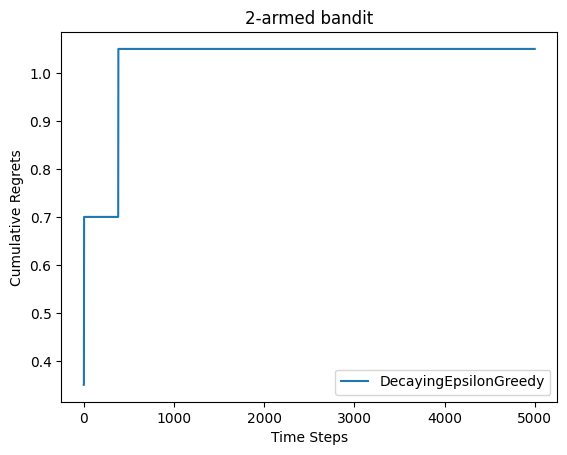

In [10]:
class DecayingEpsilonGreedy(Solver):
    """ Algoritmo epsilon-greedy cuyo valor de epsilon decae con el tiempo, hereda la clase Solver """
    def __init__(self, bandit, init_prob=1.0):
        super(DecayingEpsilonGreedy, self).__init__(bandit)
        self.Q = np.array([init_prob] * self.bandit.K)
        self.total_count = 0

    def run_one_step(self):
        self.total_count += 1
        if np.random.random() < 1/self.total_count:  # epsilon decae con el tiempo
            k = np.random.randint(0, self.bandit.K)
        else:
            k = np.argmax(self.Q)

        r = self.bandit.step(k)
        self.Q[k] += 1/(self.N[k]+1)*(r - self.Q[k])

        return k


np.random.seed(1)
decaying_epsilon_greedy_solver = DecayingEpsilonGreedy(bandit)
decaying_epsilon_greedy_solver.run(5000)
print('El lamento acumulado del algoritmo epsilon-greedy con decaimiento de epsilon es：', decaying_epsilon_greedy_solver.regret)
plot_results([decaying_epsilon_greedy_solver], ["DecayingEpsilonGreedy"])

In [11]:
actions = np.array(decaying_epsilon_greedy_solver.actions).T.tolist()
print(actions)

[0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 